[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIPI-590-XAI/Duke-AI-XAI/blob/main/assignments/xai_decathlon.ipynb)

# XAI Decathlon: Round 1 Individual Method Trial

In this lab, each student works with **one assigned explainability method** and tries to use it across ten explanation events.

The notebook gives you:

- Two trained target models: one tabular model and one image model.
- Ten event prompts with ready-to-use model objects, data objects, and assigned cases.
- A markdown results table to fill in as you go.
- A final model-profile prompt for summarizing what your method can and cannot support.

The notebook does **not** implement LIME, SHAP, PDP, ALE, Grad-CAM, Score-CAM, saliency, counterfactuals, or any other explanation method for you. That is the challenge.

**Estimated time:** 60-75 minutes  
**Format:** individual method trial  
**Deliverable:** a completed results table plus a short model profile


## Core Lesson

Different explanation methods answer different kinds of questions.

Your job is to find out where your assigned method is useful, where it is only partially useful, and where it simply does not fit the task. A method can earn a strong score for saying something clear and justified, including: "this method cannot answer this event question."

This notebook is intentionally only the individual round. Later, you may compare results with classmates who used different methods.


## Scoring Rules

For each event, assign your method one medal:

- **Gold:** directly answers the event question with convincing evidence.
- **Silver:** gives useful partial evidence, but another method or assumption is needed.
- **Bronze:** gives weak, indirect, or fragile evidence.
- **DNF:** does not finish: the method is mismatched, misleading, or not usable for the event.

A pretty visualization is not automatically a medal. Score the method based on whether it answers the event question.


## The Ten Events

| Event | Question |
|---|---|
| 1. Most Important Feature | What variable most strongly influences the tabular model's predictions? |
| 2. One Specific Prediction | Why did this individual tabular prediction occur? |
| 3. Dataset Bias or Shortcut | Is the image model relying on a spurious shortcut? |
| 4. Global Feature Effect | As one tabular feature changes, what happens to predictions? |
| 5. Compare Two Predictions | Why were two cases classified differently? |
| 6. Feature Interactions | Which tabular variables work together? |
| 7. Where Is the Model Looking? | What region of an image drives the prediction? |
| 8. Explain a Failure | Why did the model make this mistake? |
| 9. Estimate Trustworthiness | Should a human trust this prediction? |
| 10. Reverse Engineer Strategy | What strategy has each model learned? |

## Results Table

Edit this markdown cell as you work through the events. Keep each evidence claim short enough that someone else can understand what your method showed and why you assigned the medal.

**My assigned method:** SHAP: TreeSHAP (+ SHAP interaction values) for the tabular model; patch-level KernelSHAP (8×8 grid) for the image model

| Event | Question | Medal | Evidence from my method | Limitations or notes |
|---|---|---|---|---|
| 1. Most Important Feature | What variable most strongly influences the tabular model's predictions? | 🥇 Gold | Mean \|SHAP\| ranks `debt_ratio` first (≈0.074), then `zip_proxy` (≈0.053) and `recent_late_payments` (≈0.046); `app_minutes`, `age`, `support_tickets` ≈ 0. | Credit is split among correlated features; `zip_proxy` may be absorbing some debt/income signal. Its high rank is a proxy red flag. |
| 2. One Specific Prediction | Why did this individual tabular prediction occur? | 🥇 Gold | Waterfall for row 718 (P=0.499): `zip_proxy=1` adds +0.154; low income/savings and 2 late payments add ≈+0.04 each; low debt subtracts −0.025. Sums exactly to the prediction. | Explains relative to an average-applicant baseline; does not say what would need to change (that's counterfactuals). |
| 3. Dataset Bias or Shortcut | Is the image model relying on a spurious shortcut? | 🥇 Gold | Circle *with* marker: marker patches add +1.00 to P(square) while the circle subtracts −0.10. Square *without* marker: marker SHAP 0, P(square)=0.065. Marker patches (6% of area) carry ≈87% of all attribution across 26 sampled marker images. | Depends on patch size and the "blank" baseline; a red patch on gray is especially easy for masking to detect. |
| 4. Global Feature Effect | As one tabular feature changes, what happens to predictions? | 🥈 Silver | Dependence plot: `debt_ratio` effect is monotonic: mean SHAP ≈ −0.07 below 0.22, ≈ 0 around 0.3, +0.18 above 0.48; `income_k` pushes the other way. | Shows change in *contribution*, not change in *prediction* with everything else held fixed; spread reflects interactions and correlation. PDP/ALE is the right tool. |
| 5. Compare Two Predictions | Why were two cases classified differently? | 🥇 Gold | Same base value → the 0.766 prediction gap splits exactly: debt 0.54 vs 0.04 (≈+0.23), 6 vs 0 late payments (≈+0.21), zip_proxy 1 vs 0 (≈+0.13). Two true squares differ only by marker SHAP (+0.98 vs 0). | Compares two fixed rows; does not find the minimal change that flips a decision. |
| 6. Feature Interactions | Which tabular variables work together? | 🥈 Silver | SHAP interaction values: top pairs `debt_ratio×late_payments`, `income×zip_proxy`, `debt×zip_proxy`. Targeted test confirms a real `age×debt_ratio` effect for under-30s with high debt (≈+0.009 vs ≈0 otherwise). | Global ranking is inflated by correlated features and understates rare-but-real interactions (only ~3% of rows). Pairwise only; tree-specific. |
| 7. Where Is the Model Looking? | What region of an image drives the prediction? | 🥇 Gold | For every marker image the top-attributed patches are the top-left marker patches; the central shape gets little or negative attribution. Stable across KernelSHAP seeds (corr ≈ 1.0). | 8×8-pixel resolution; baseline choice matters. Pixel-level methods (Integrated Gradients) would be sharper. |
| 8. Explain a Failure | Why did the model make this mistake? | 🥈 Silver | Image: circle called square (P=0.98) because the marker adds +1.00. Tabular: true high-risk applicant scored 0.40; high debt (+0.24) was offset by only 1 late payment and `zip_proxy=0`. | Gold for the image failure. For the tabular case, SHAP shows what the model used but not what it missed or why the true label differed. |
| 9. Estimate Trustworthiness | Should a human trust this prediction? | 🥈 Silver | Image shortcut probe: don't trust it (confidence comes almost entirely from the marker). Tabular borderline case: stable explanation, but 42% of it is a location proxy → flag for review. | SHAP can show *untrustworthy reasoning* but cannot certify correctness; no calibration, uncertainty, or out-of-distribution signal. |
| 10. Reverse Engineer Strategy | What strategy has each model learned? | 🥈 Silver | Image: "marker → square, no marker → circle" (predicts square for 100% of marker images, 0% otherwise). Tabular: financially sensible directions, but heavy reliance on `zip_proxy` and some on `promo_seen`. | Shows *what* and *which direction*, not effect shapes, minimal decision changes, or why proxies carry signal. |

**Medal count:** 🥇 5 Gold · 🥈 5 Silver · 🥉 0 Bronze · DNF 0

In [1]:
#@title Setup
# Run this cell first. It imports only the libraries needed to create the target models.
# You may add your own XAI imports later in the "Your method implementation" section.

import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

SEED = 42
rng = np.random.default_rng(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


In [2]:
#@title Event guide helper
# This table points you to the model/data objects for each event.

EVENTS = [
    "1. Most important feature",
    "2. One specific prediction",
    "3. Dataset bias or shortcut",
    "4. Global feature effect",
    "5. Compare two predictions",
    "6. Feature interactions",
    "7. Where is the model looking?",
    "8. Explain a failure",
    "9. Estimate trustworthiness",
    "10. Reverse engineer strategy",
]

event_guide = pd.DataFrame({
    "event": EVENTS,
    "target": [
        "Tabular risk model",
        "Tabular risk model",
        "Image shortcut model",
        "Tabular risk model",
        "Tabular or image cases",
        "Tabular risk model",
        "Image shortcut model",
        "Tabular or image failure case",
        "Either target model",
        "Both target models",
    ],
    "primary_objects": [
        "risk_model, X_train, X_test, feature_names, predict_risk_proba",
        "tabular_local_case, X_test, predict_risk_proba",
        "image_shortcut_case, image_reference_case, test_imgs, predict_image_proba",
        "X_train, X_test, feature_names, predict_risk_proba",
        "tabular_low_case vs tabular_high_case, or assigned_image_cases",
        "X_train, X_test, feature_names, predict_risk_proba",
        "image_model, test_imgs, assigned_image_cases, show_image_case",
        "tabular_failure_case or image_failure_case",
        "assigned cases, predicted probabilities, explanation stability checks",
        "all model interfaces and prior event evidence",
    ],
    "question_type": [
        "global feature importance",
        "local prediction explanation",
        "shortcut or bias diagnosis",
        "global feature effect",
        "contrastive explanation",
        "interaction discovery",
        "spatial localization",
        "failure diagnosis",
        "trust and uncertainty judgment",
        "synthesis and model profiling",
    ],
})

event_guide


,event,target,primary_objects,question_type
0,1. Most important feature,Tabular risk model,"risk_model, X_train, X_test, feature_names, pr...",global feature importance
1,2. One specific prediction,Tabular risk model,"tabular_local_case, X_test, predict_risk_proba",local prediction explanation
2,3. Dataset bias or shortcut,Image shortcut model,"image_shortcut_case, image_reference_case, tes...",shortcut or bias diagnosis
3,4. Global feature effect,Tabular risk model,"X_train, X_test, feature_names, predict_risk_p...",global feature effect
4,5. Compare two predictions,Tabular or image cases,"tabular_low_case vs tabular_high_case, or assi...",contrastive explanation
5,6. Feature interactions,Tabular risk model,"X_train, X_test, feature_names, predict_risk_p...",interaction discovery
6,7. Where is the model looking?,Image shortcut model,"image_model, test_imgs, assigned_image_cases, ...",spatial localization
7,8. Explain a failure,Tabular or image failure case,tabular_failure_case or image_failure_case,failure diagnosis
8,9. Estimate trustworthiness,Either target model,"assigned cases, predicted probabilities, expla...",trust and uncertainty judgment
9,10. Reverse engineer strategy,Both target models,all model interfaces and prior event evidence,synthesis and model profiling


# Target Model 1: Tabular Risk Model

You are given a trained model that predicts whether a synthetic applicant is **high risk**.

The model sees these features:

- `age`
- `income_k`
- `debt_ratio`
- `loyalty_years`
- `recent_late_payments`
- `savings_k`
- `app_minutes`
- `support_tickets`
- `zip_proxy`
- `promo_seen`

Treat this as a model you need to investigate. Some variables are directly meaningful, some are weak, some may act like shortcuts, and some may interact.

In [3]:
#@title Create the tabular data and train the risk model

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def make_tabular_data(n=3000, seed=SEED):
    rng = np.random.default_rng(seed)
    age = rng.integers(18, 76, size=n)
    income_k = np.clip(rng.normal(72, 24, size=n), 18, 180)
    debt_ratio = np.clip(rng.beta(2.2, 5.0, size=n), 0.01, 0.98)
    loyalty_years = np.clip((age - 18) * rng.beta(1.5, 6.0, size=n), 0, 35)
    recent_late_payments = rng.poisson(0.65 + 1.8 * debt_ratio, size=n)
    savings_k = np.clip(rng.lognormal(mean=2.35, sigma=0.8, size=n), 0, 120)
    app_minutes = np.clip(rng.normal(18, 7, size=n), 2, 60)
    support_tickets = rng.poisson(0.3 + 0.5 * (debt_ratio > 0.45), size=n)

    zip_proxy = rng.binomial(1, sigmoid(-0.9 + 1.9 * debt_ratio - 0.012 * income_k), size=n)
    promo_seen = rng.binomial(1, sigmoid(-0.3 + 1.4 * zip_proxy + 0.8 * (age < 30)), size=n)
    young_high_debt = ((age < 30) & (debt_ratio > 0.48)).astype(float)

    logit = (
        -1.9
        + 3.8 * debt_ratio
        + 0.38 * recent_late_payments
        - 0.018 * income_k
        - 0.024 * savings_k
        - 0.045 * loyalty_years
        + 0.85 * zip_proxy
        + 0.55 * promo_seen
        + 1.25 * young_high_debt
        + 0.025 * support_tickets
        + rng.normal(0, 0.45, size=n)
    )
    p = sigmoid(logit)
    y = rng.binomial(1, p)

    X = pd.DataFrame({
        "age": age,
        "income_k": income_k,
        "debt_ratio": debt_ratio,
        "loyalty_years": loyalty_years,
        "recent_late_payments": recent_late_payments,
        "savings_k": savings_k,
        "app_minutes": app_minutes,
        "support_tickets": support_tickets,
        "zip_proxy": zip_proxy,
        "promo_seen": promo_seen,
    })
    return X, pd.Series(y, name="high_risk")

X, y = make_tabular_data()
feature_names = X.columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

risk_model = RandomForestClassifier(
    n_estimators=220,
    max_depth=7,
    min_samples_leaf=12,
    random_state=SEED,
    n_jobs=-1,
)
risk_model.fit(X_train, y_train)

tabular_pred = risk_model.predict(X_test)
tabular_proba = risk_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, tabular_pred), 3))
print("Positive class rate in test set:", round(float(y_test.mean()), 3))
print(classification_report(y_test, tabular_pred, target_names=["low risk", "high risk"]))
X_train.head()

Accuracy: 0.805
Positive class rate in test set: 0.224
              precision    recall  f1-score   support

    low risk       0.81      0.97      0.89       582
   high risk       0.70      0.23      0.34       168

    accuracy                           0.81       750
   macro avg       0.76      0.60      0.61       750
weighted avg       0.79      0.81      0.76       750



,age,income_k,debt_ratio,loyalty_years,recent_late_payments,savings_k,app_minutes,support_tickets,zip_proxy,promo_seen
1583,42,60.186070,0.178157,3.750431,2,12.938567,8.853330,1,0,1
1035,61,125.055381,0.136064,3.955724,0,7.920787,8.808620,0,0,1
657,54,74.580820,0.488986,16.918809,1,2.733885,18.188498,0,0,0
968,71,71.595919,0.282121,7.306052,0,2.729296,19.732005,1,0,1
2298,30,81.528758,0.200992,0.374701,2,4.948344,13.871067,0,1,1


In [4]:
#@title Tabular model interface and assigned cases
# These are allowed utilities. They expose the model and selected cases, but they do not explain the model.

def predict_risk_proba(data):
    """Return [P(low risk), P(high risk)] for rows with the tabular feature columns."""
    if isinstance(data, pd.DataFrame):
        df = data[feature_names]
    else:
        df = pd.DataFrame(data, columns=feature_names)
    return risk_model.predict_proba(df)

def first_distinct(candidates, used=(), fallback=0):
    """Pick the first candidate that is not already used."""
    for idx in candidates:
        idx = int(idx)
        if idx not in used:
            return idx
    return int(fallback)

# Cases for local, comparison, and failure events.
tabular_low_case = int(np.argmin(tabular_proba))
tabular_high_case = int(np.argmax(tabular_proba))
near_boundary_rows = np.argsort(np.abs(tabular_proba - 0.5))
tabular_local_case = first_distinct(near_boundary_rows, used={tabular_low_case, tabular_high_case})
wrong_rows = np.where(tabular_pred != y_test.to_numpy())[0]
tabular_failure_case = first_distinct(
    wrong_rows,
    used={tabular_local_case, tabular_low_case, tabular_high_case},
    fallback=tabular_local_case,
)

assigned_tabular_cases = pd.DataFrame({
    "case_name": ["local_case", "low_case", "high_case", "failure_case"],
    "row_index_in_X_test": [tabular_local_case, tabular_low_case, tabular_high_case, tabular_failure_case],
    "true_label": [
        int(y_test.iloc[tabular_local_case]),
        int(y_test.iloc[tabular_low_case]),
        int(y_test.iloc[tabular_high_case]),
        int(y_test.iloc[tabular_failure_case]),
    ],
    "predicted_label": [
        int(tabular_pred[tabular_local_case]),
        int(tabular_pred[tabular_low_case]),
        int(tabular_pred[tabular_high_case]),
        int(tabular_pred[tabular_failure_case]),
    ],
    "predicted_P_high_risk": [
        round(float(tabular_proba[tabular_local_case]), 3),
        round(float(tabular_proba[tabular_low_case]), 3),
        round(float(tabular_proba[tabular_high_case]), 3),
        round(float(tabular_proba[tabular_failure_case]), 3),
    ],
})

assigned_tabular_cases

,case_name,row_index_in_X_test,true_label,predicted_label,predicted_P_high_risk
0,local_case,718,0,0,0.499
1,low_case,565,0,0,0.022
2,high_case,564,1,1,0.789
3,failure_case,1,1,0,0.400


# Target Model 2: Image Shortcut Model

You are given a tiny image classifier trained on synthetic images.

- Class `0`: circle
- Class `1`: square

The training data may contain a shortcut. The test set is designed so you can investigate whether the model learned the intended shape concept, a shortcut, or both.

In [5]:
#@title Create the image data and train the image model

def draw_shape_image(label, marker=None, seed=None, image_size=64):
    rng = np.random.default_rng(seed)
    img = np.ones((image_size, image_size, 3), dtype=np.float32) * 0.92
    img += rng.normal(0, 0.025, size=img.shape).astype(np.float32)
    img = np.clip(img, 0, 1)

    yy, xx = np.mgrid[:image_size, :image_size]
    cx = image_size // 2 + int(rng.integers(-5, 6))
    cy = image_size // 2 + int(rng.integers(-5, 6))

    color = np.array([0.20, 0.22, 0.24])
    if label == 0:
        radius = int(rng.integers(10, 18))
        mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= radius ** 2
    else:
        half = int(rng.integers(9, 17))
        mask = (np.abs(xx - cx) <= half) & (np.abs(yy - cy) <= half)

    img[mask] = color

    # The marker is part of the data-generation process. Whether it is fair evidence is for you to investigate.
    if marker is None:
        marker = rng.random() < (0.98 if label == 1 else 0.02)
    if marker:
        img[3:15, 3:15, :] = np.array([0.95, 0.08, 0.08])

    return np.clip(img, 0, 1), int(marker)


def make_image_dataset(n=800, seed=SEED, balanced_markers=False):
    rng = np.random.default_rng(seed)
    images, labels, markers = [], [], []
    for i in range(n):
        label = int(rng.integers(0, 2))
        marker = None
        if balanced_markers:
            marker = bool(rng.integers(0, 2))
        img, has_marker = draw_shape_image(label, marker=marker, seed=seed + i)
        images.append(img)
        labels.append(label)
        markers.append(has_marker)
    return np.stack(images), np.array(labels), np.array(markers)

train_imgs, train_y, train_marker = make_image_dataset(800, seed=10, balanced_markers=False)
test_imgs, test_y, test_marker = make_image_dataset(320, seed=5000, balanced_markers=True)

class TinyShapeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 12, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(12, 24, kernel_size=5, padding=2)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(24 * 16 * 16, 48)
        self.fc2 = nn.Linear(48, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


def to_tensor_images(images):
    return torch.tensor(images.transpose(0, 3, 1, 2), dtype=torch.float32)

train_ds = TensorDataset(to_tensor_images(train_imgs), torch.tensor(train_y, dtype=torch.long))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

image_model = TinyShapeCNN().to(DEVICE)
optimizer = torch.optim.Adam(image_model.parameters(), lr=1e-3)

image_model.train()
for epoch in range(4):
    losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = F.cross_entropy(image_model(xb), yb)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    print(f"epoch {epoch + 1}: loss={np.mean(losses):.4f}")

image_model.eval()
with torch.no_grad():
    logits = image_model(to_tensor_images(test_imgs).to(DEVICE))
    image_proba = F.softmax(logits, dim=1).cpu().numpy()
    image_pred = image_proba.argmax(axis=1)

print("Test accuracy:", round(accuracy_score(test_y, image_pred), 3))
print("Confusion matrix:\n", confusion_matrix(test_y, image_pred))

epoch 1: loss=0.6576


epoch 2: loss=0.2582


epoch 3: loss=0.0858


epoch 4: loss=0.0955
Test accuracy: 0.494
Confusion matrix:
 [[68 84]
 [78 90]]


In [6]:
#@title Image model interface and assigned cases
# These are allowed utilities. They expose the model and selected cases, but they do not explain the model.

def predict_image_proba(images_np):
    """Return [P(circle), P(square)] for images shaped as N x 64 x 64 x 3."""
    image_model.eval()
    with torch.no_grad():
        xb = to_tensor_images(np.asarray(images_np)).to(DEVICE)
        probs = F.softmax(image_model(xb), dim=1).cpu().numpy()
    return probs


def show_image_case(idx, title_prefix=""):
    probs = predict_image_proba(test_imgs[[idx]])[0]
    plt.imshow(test_imgs[idx])
    plt.axis("off")
    plt.title(
        f"{title_prefix}idx={idx} true={test_y[idx]} pred={probs.argmax()} "
        f"P(square)={probs[1]:.3f} marker={test_marker[idx]}"
    )
    plt.show()

def first_distinct(candidates, used=(), fallback=0):
    """Pick the first candidate that is not already used."""
    for idx in candidates:
        idx = int(idx)
        if idx not in used:
            return idx
    return int(fallback)

image_wrong = np.where(image_pred != test_y)[0]
marker_present_circle = np.where((test_marker == 1) & (test_y == 0))[0]
marker_present_square = np.where((test_marker == 1) & (test_y == 1))[0]
marker_absent_square = np.where((test_marker == 0) & (test_y == 1))[0]
image_shortcut_case = first_distinct(marker_present_circle, fallback=0)
image_reference_case = first_distinct(marker_present_square, used={image_shortcut_case}, fallback=0)
image_contrast_case = first_distinct(
    marker_absent_square,
    used={image_shortcut_case, image_reference_case},
    fallback=1,
)
image_failure_case = first_distinct(
    image_wrong,
    used={image_shortcut_case, image_reference_case, image_contrast_case},
    fallback=image_contrast_case,
)

assigned_image_cases = pd.DataFrame({
    "case_name": ["shortcut_probe", "reference_square", "contrast_square", "failure_case"],
    "image_index": [image_shortcut_case, image_reference_case, image_contrast_case, image_failure_case],
    "true_label": [
        int(test_y[image_shortcut_case]),
        int(test_y[image_reference_case]),
        int(test_y[image_contrast_case]),
        int(test_y[image_failure_case]),
    ],
    "marker_present": [
        int(test_marker[image_shortcut_case]),
        int(test_marker[image_reference_case]),
        int(test_marker[image_contrast_case]),
        int(test_marker[image_failure_case]),
    ],
    "predicted_label": [
        int(image_pred[image_shortcut_case]),
        int(image_pred[image_reference_case]),
        int(image_pred[image_contrast_case]),
        int(image_pred[image_failure_case]),
    ],
    "predicted_P_square": [
        round(float(image_proba[image_shortcut_case, 1]), 3),
        round(float(image_proba[image_reference_case, 1]), 3),
        round(float(image_proba[image_contrast_case, 1]), 3),
        round(float(image_proba[image_failure_case, 1]), 3),
    ],
})

assigned_image_cases

,case_name,image_index,true_label,marker_present,predicted_label,predicted_P_square
0,shortcut_probe,5,0,1,1,0.980
1,reference_square,2,1,1,1,0.986
2,contrast_square,4,1,0,0,0.065
3,failure_case,6,0,1,1,0.980


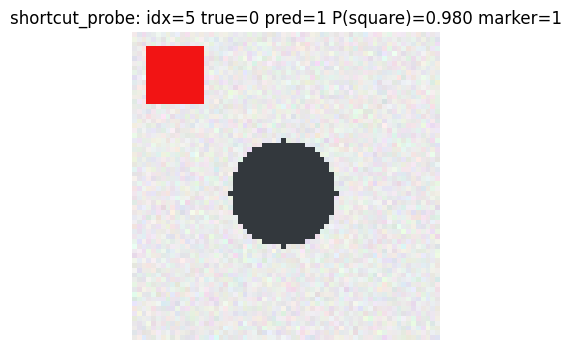

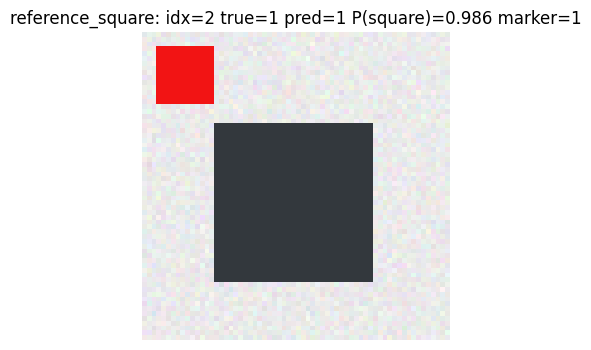

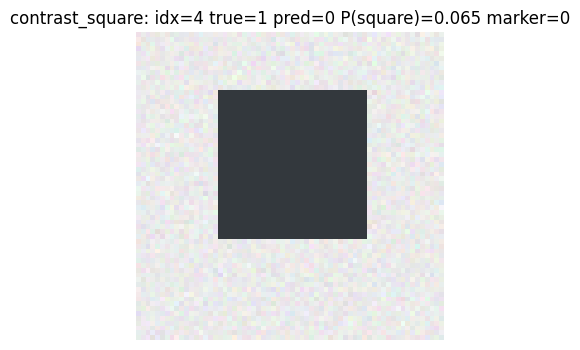

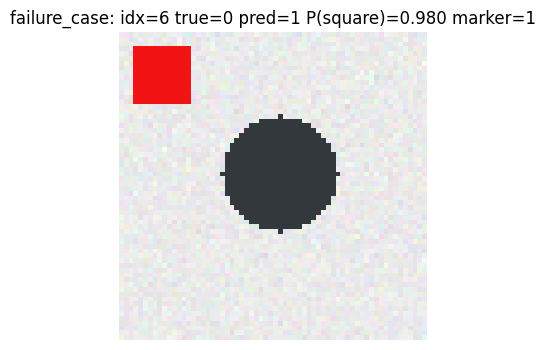

In [7]:
#@title View the assigned image cases
for name, idx in zip(assigned_image_cases["case_name"], assigned_image_cases["image_index"]):
    show_image_case(int(idx), title_prefix=f"{name}: ")

# Your Method Implementation

Use this section to install packages, import libraries, write helper functions, and adapt your assigned XAI method.

You may use external documentation. You may also decide that your method cannot reasonably be applied to an event, but you must explain why.

Suggested workflow:

1. Identify what inputs your method needs: tabular rows, images, gradients, model probabilities, labels, background data, perturbed samples, etc.
2. Decide whether your method is local, global, visual, counterfactual, or something else.
3. Implement the smallest version that can answer one event.
4. Reuse and adapt it across events.
5. Record both successes and failures honestly.


In [8]:
# Your implementation scratchpad.
# Assigned method for all ten events: SHAP (SHapley Additive exPlanations)
#   - Tabular model -> TreeSHAP (exact Shapley values for tree ensembles) + SHAP interaction values
#   - Image model   -> KernelSHAP over an 8x8 grid of image patches ("superpixel" Shapley values)
# Source: Lundberg & Lee (2017), "A Unified Approach to Interpreting Model Predictions";
#         Lundberg et al. (2020), "From local explanations to global understanding with explainable AI for trees";
#         shap library docs: https://shap.readthedocs.io

try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

print("shap version:", shap.__version__)
print("Event guide:")
display(event_guide)

# ---------------- Tabular: TreeSHAP ----------------
tree_explainer = shap.TreeExplainer(risk_model)
shap_exp_all = tree_explainer(X_test)          # Explanation, shape (n, features, 2 classes)
shap_exp = shap_exp_all[:, :, 1]               # keep the "high risk" class
sv = shap_exp.values                           # (750, 10) SHAP values in probability units
base_value = float(tree_explainer.expected_value[1])

# Sanity check (local accuracy / additivity): base value + sum of SHAP values = model output
recon = base_value + sv.sum(axis=1)
print("Base value (avg P(high risk) over training data):", round(base_value, 3))
print("Max additivity error:", float(np.abs(recon - tabular_proba).max()))

def shap_row_table(i):
    """Row-level SHAP table for one X_test row, sorted by absolute contribution."""
    return (pd.DataFrame({"feature_value": X_test.iloc[i], "shap_value": sv[i]})
              .assign(abs_shap=lambda d: d.shap_value.abs())
              .sort_values("abs_shap", ascending=False)
              .drop(columns="abs_shap")
              .round(3))

# ---------------- Image: patch-level KernelSHAP ----------------
# Players in the Shapley game = 64 patches (8x8 grid of 8x8-pixel squares).
# A patch that is "absent" from a coalition is replaced with the plain background gray (0.92).
# The output being explained is P(square).
PATCH = 8
GRID = 64 // PATCH
BACKGROUND_GRAY = 0.92
MARKER_PATCHES = [(0, 0), (0, 1), (1, 0), (1, 1)]   # the red marker occupies pixels [3:15, 3:15]

def make_masked_predict(img):
    def f(z):
        z = np.asarray(z)
        out = np.empty((len(z), 64, 64, 3), dtype=np.float32)
        for k, zz in enumerate(z):
            m = np.kron(zz.reshape(GRID, GRID), np.ones((PATCH, PATCH)))[:, :, None]
            out[k] = img * m + BACKGROUND_GRAY * (1 - m)
        return predict_image_proba(out)[:, 1]
    return f

def image_patch_shap(idx, nsamples=1500, seed=0):
    """Return (8x8 SHAP map for P(square), base value) for test image idx."""
    f = make_masked_predict(test_imgs[idx])
    kx = shap.KernelExplainer(f, np.zeros((1, GRID * GRID)))   # baseline = all patches blanked
    np.random.seed(seed)
    vals = kx.shap_values(np.ones((1, GRID * GRID)), nsamples=nsamples, silent=True)
    return np.asarray(vals).reshape(GRID, GRID), float(np.ravel(kx.expected_value)[0])

def marker_vs_rest(shap_map):
    marker = sum(shap_map[p] for p in MARKER_PATCHES)
    return float(marker), float(shap_map.sum() - marker)

def plot_image_shap(idx, shap_map, ax_img, ax_map, title=""):
    lim = max(np.abs(shap_map).max(), 1e-6)
    ax_img.imshow(test_imgs[idx]); ax_img.axis("off")
    ax_img.set_title(f"{title}\ntrue={test_y[idx]} pred={image_pred[idx]} P(sq)={image_proba[idx,1]:.2f}", fontsize=9)
    ax_map.imshow(test_imgs[idx].mean(axis=2), cmap="gray", alpha=0.35)
    im = ax_map.imshow(np.kron(shap_map, np.ones((PATCH, PATCH))), cmap="bwr", vmin=-lim, vmax=lim, alpha=0.75)
    ax_map.axis("off"); ax_map.set_title("SHAP for P(square)\nred=pushes toward square", fontsize=9)
    return im

# Pre-compute patch SHAP maps for the four assigned image cases (reused in Events 3, 5, 7, 8, 9)
image_shap = {}
for name, idx in zip(assigned_image_cases["case_name"], assigned_image_cases["image_index"]):
    image_shap[name] = image_patch_shap(int(idx))
    mk, rest = marker_vs_rest(image_shap[name][0])
    print(f"{name:17s} idx={int(idx)}  marker-patch SHAP={mk:+.3f}  all-other-patch SHAP={rest:+.3f}")

shap version: 0.51.0
Event guide:


,event,target,primary_objects,question_type
0,1. Most important feature,Tabular risk model,"risk_model, X_train, X_test, feature_names, pr...",global feature importance
1,2. One specific prediction,Tabular risk model,"tabular_local_case, X_test, predict_risk_proba",local prediction explanation
2,3. Dataset bias or shortcut,Image shortcut model,"image_shortcut_case, image_reference_case, tes...",shortcut or bias diagnosis
3,4. Global feature effect,Tabular risk model,"X_train, X_test, feature_names, predict_risk_p...",global feature effect
4,5. Compare two predictions,Tabular or image cases,"tabular_low_case vs tabular_high_case, or assi...",contrastive explanation
5,6. Feature interactions,Tabular risk model,"X_train, X_test, feature_names, predict_risk_p...",interaction discovery
6,7. Where is the model looking?,Image shortcut model,"image_model, test_imgs, assigned_image_cases, ...",spatial localization
7,8. Explain a failure,Tabular or image failure case,tabular_failure_case or image_failure_case,failure diagnosis
8,9. Estimate trustworthiness,Either target model,"assigned cases, predicted probabilities, expla...",trust and uncertainty judgment
9,10. Reverse engineer strategy,Both target models,all model interfaces and prior event evidence,synthesis and model profiling


Base value (avg P(high risk) over training data): 0.224
Max additivity error: 1.6653345369377348e-15


shortcut_probe    idx=5  marker-patch SHAP=+1.000  all-other-patch SHAP=-0.101


reference_square  idx=2  marker-patch SHAP=+0.982  all-other-patch SHAP=-0.076


contrast_square   idx=4  marker-patch SHAP=+0.000  all-other-patch SHAP=-0.015


failure_case      idx=6  marker-patch SHAP=+0.999  all-other-patch SHAP=-0.099


## Individual Event Checklist

For each event, produce four things:

- **Output:** the plot, table, heatmap, counterfactual, ranking, or diagnostic your method produced.
- **Claim:** one sentence answering the event question, or saying the method cannot answer it.
- **Evidence quality:** why the output does or does not support the claim.
- **Medal:** Gold, Silver, Bronze, or DNF.

After each event, fill in the markdown Results Table near the top of the notebook. A DNF is not a failure of the student. It is evidence about the method's scope.


## Event 1: Find the Most Important Feature

**Question:** What variable most strongly influences the tabular model's predictions?

**Target:** Tabular risk model

**Your task:** Produce evidence that ranks or compares the influence of multiple features. If your method cannot produce global feature importance, explain the mismatch.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

,mean_abs_SHAP
debt_ratio,0.0741
zip_proxy,0.0534
recent_late_payments,0.0460
income_k,0.0285
savings_k,0.0149
promo_seen,0.0145
loyalty_years,0.0129
app_minutes,0.0064
age,0.0059
support_tickets,0.0047


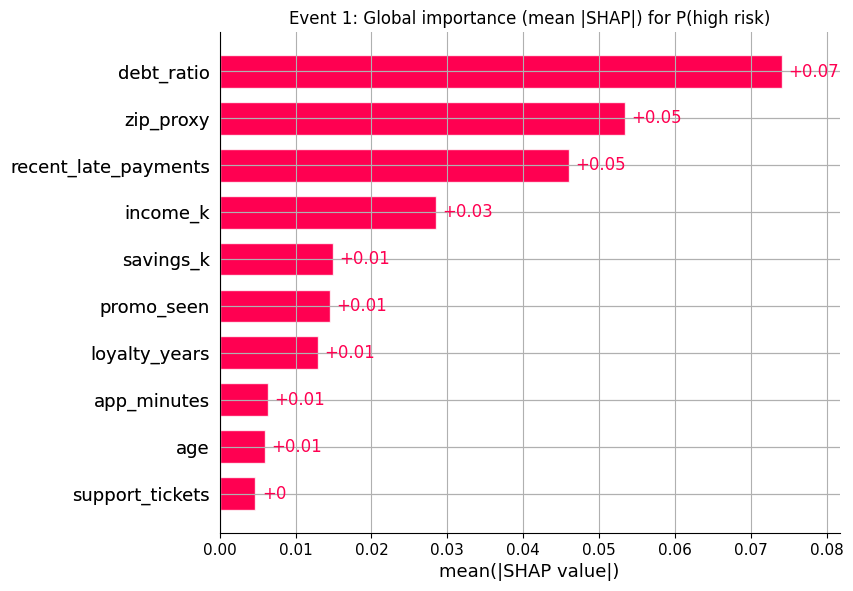

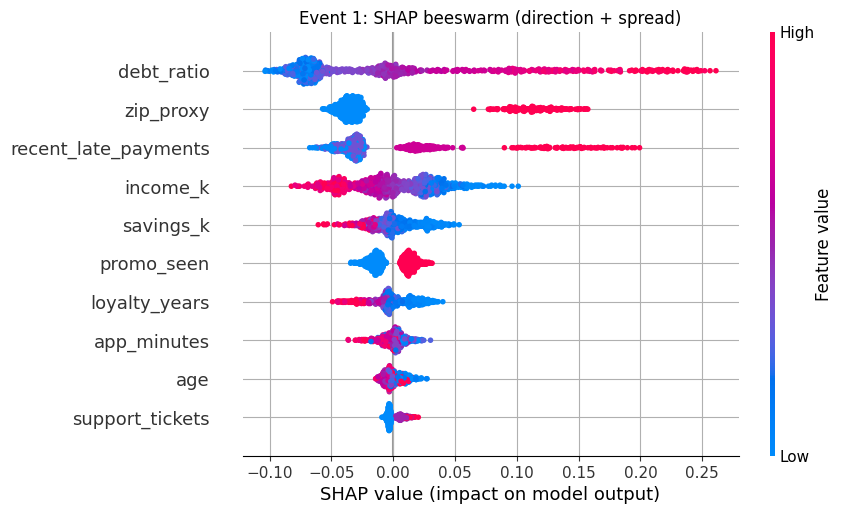

,corr_with_zip_proxy
zip_proxy,1.00
debt_ratio,0.16
income_k,-0.16
promo_seen,0.25
age,-0.01


In [9]:
# Event 1: Global importance = mean |SHAP value| across the test set
global_importance = (pd.Series(np.abs(sv).mean(axis=0), index=feature_names)
                       .sort_values(ascending=False).round(4))
display(global_importance.to_frame("mean_abs_SHAP"))

shap.plots.bar(shap_exp, max_display=10, show=False)
plt.title("Event 1: Global importance (mean |SHAP|) for P(high risk)"); plt.show()

shap.plots.beeswarm(shap_exp, max_display=10, show=False)
plt.title("Event 1: SHAP beeswarm (direction + spread)"); plt.show()

# Proxy check: zip_proxy ranks high. How correlated is it with legitimate financial features?
display(X_train[["zip_proxy", "debt_ratio", "income_k", "promo_seen", "age"]].corr().round(2)["zip_proxy"].to_frame("corr_with_zip_proxy"))

**Event 1: result**

- **What the method produced:** a ranking of all 10 features by mean |SHAP|, plus a beeswarm plot showing which direction each feature pushes predictions.
- **Claim:** `debt_ratio` has the most influence (mean |SHAP| ≈ 0.074). Next come `zip_proxy` (≈ 0.053) and `recent_late_payments` (≈ 0.046). `app_minutes`, `age` and `support_tickets` contribute close to nothing.
- **How strong is the evidence:** strong. TreeSHAP computes exact Shapley values for this random forest, and the additivity check passes (base value + SHAP values = predicted probability). The beeswarm confirms the directions make sense: higher debt pushes risk up, higher income pushes it down.
- **Caveat:** Shapley values split credit among correlated features. `zip_proxy` is only modestly correlated with `debt_ratio` (r ≈ 0.16) and `income_k` (r ≈ −0.16), so most of its importance is its own. That's the red flag: a location proxy ranks above income.
- **Medal: 🥇 Gold**

## Event 2: Explain One Specific Prediction

**Question:** Why did this individual tabular prediction occur?

**Target:** Tabular local case

**Your task:** Use `tabular_local_case` and explain the model's prediction for that row. Your answer should refer to row-specific evidence.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

Row 718: true label=0, P(high risk)=0.499


,feature_value,shap_value
zip_proxy,1.000,0.154
income_k,48.897,0.047
savings_k,1.147,0.045
recent_late_payments,2.000,0.041
debt_ratio,0.281,-0.025
app_minutes,13.106,0.018
loyalty_years,8.981,-0.014
promo_seen,1.000,0.014
age,38.000,-0.003
support_tickets,0.000,-0.003


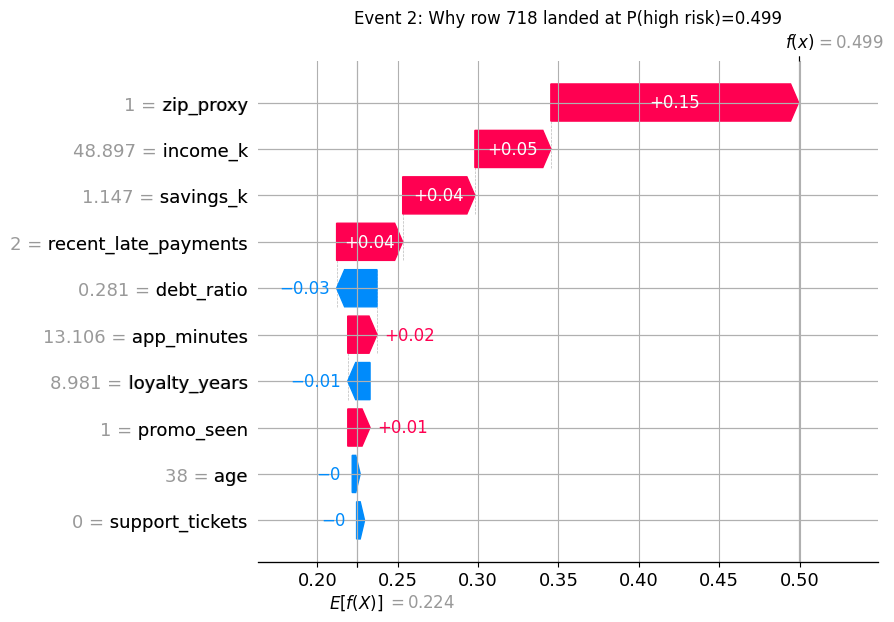

In [10]:
# Event 2: Local explanation for the near-boundary case
i = tabular_local_case
print(f"Row {i}: true label={int(y_test.iloc[i])}, P(high risk)={tabular_proba[i]:.3f}")
display(shap_row_table(i))
shap.plots.waterfall(shap_exp[i], max_display=10, show=False)
plt.title(f"Event 2: Why row {i} landed at P(high risk)={tabular_proba[i]:.3f}"); plt.show()

**Event 2: result**

- **What the method produced:** a waterfall plot and a table showing how each feature moves this one applicant from the base rate (≈ 0.224) to the model's output of 0.499.
- **Claim:** the case sits right on the decision boundary mainly because of `zip_proxy = 1` (+0.154). Smaller pushes toward risk come from low income, low savings and 2 late payments (≈ +0.04 each). Its low `debt_ratio` (0.28) pulls the other way (−0.025). Without the zip code proxy, this applicant would be clearly low risk.
- **How strong is the evidence:** strong and specific to this row. The contributions add up exactly to the prediction. The explanation also exposes a fairness problem: the single biggest reason is location, not financial behavior.
- **Caveat:** SHAP values are measured against a baseline (the average applicant). They tell you *what moved this prediction*, not *what the applicant would need to change* to get a different outcome; that would need counterfactuals.
- **Medal: 🥇 Gold**

## Event 3: Detect Dataset Bias or a Shortcut

**Question:** Is the image model relying on a spurious shortcut?

**Target:** Image shortcut probe

**Your task:** Investigate whether the classifier uses the red corner marker, the shape, or both. Your method may need adaptation if it is not an image method.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

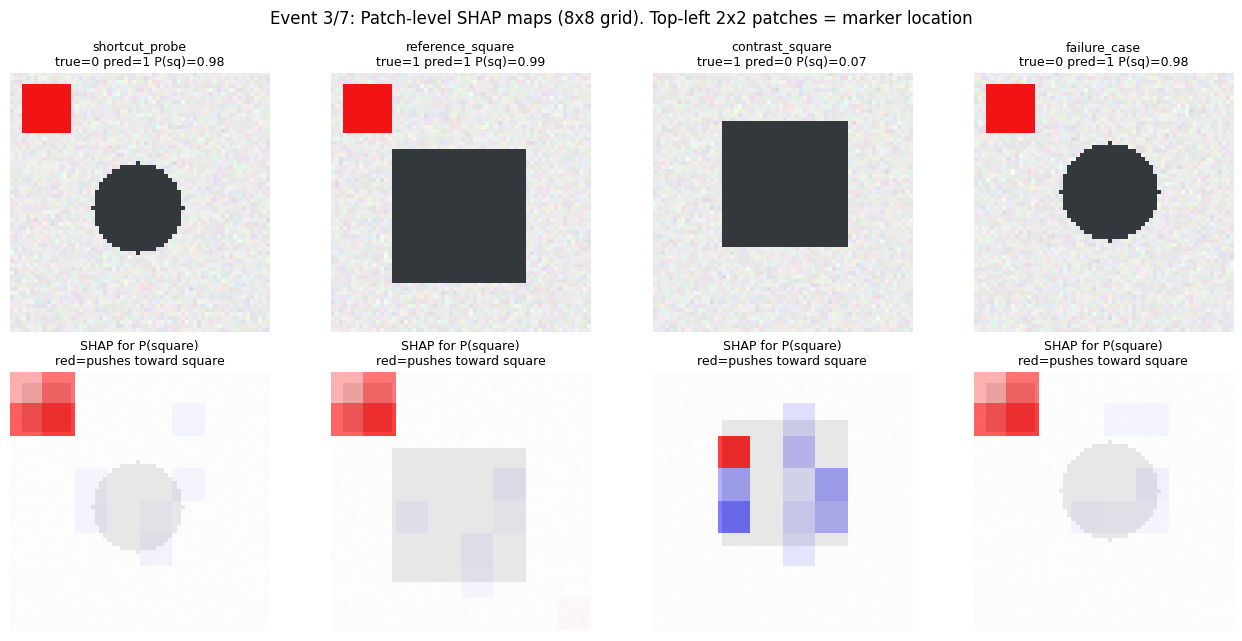

,case,true_label,marker,P_square,marker_patch_SHAP,shape_and_other_patch_SHAP
0,shortcut_probe,0,1,0.980,1.000,-0.101
1,reference_square,1,1,0.986,0.982,-0.076
2,contrast_square,1,0,0.065,0.000,-0.015
3,failure_case,0,1,0.980,0.999,-0.099


Across 26 sampled marker images, marker patches account for 87% of total |SHAP| (they are 4/64 = 6% of the image area).


In [11]:
# Event 3: Is the image model using the red corner marker?
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for col, name in enumerate(["shortcut_probe", "reference_square", "contrast_square", "failure_case"]):
    idx = int(assigned_image_cases.set_index("case_name").loc[name, "image_index"])
    plot_image_shap(idx, image_shap[name][0], axes[0, col], axes[1, col], title=name)
plt.suptitle("Event 3/7: Patch-level SHAP maps (8x8 grid). Top-left 2x2 patches = marker location")
plt.tight_layout(); plt.show()

summary = pd.DataFrame([
    dict(case=name, true_label=int(test_y[idx]), marker=int(test_marker[idx]),
         P_square=round(float(image_proba[idx, 1]), 3),
         marker_patch_SHAP=round(marker_vs_rest(image_shap[name][0])[0], 3),
         shape_and_other_patch_SHAP=round(marker_vs_rest(image_shap[name][0])[1], 3))
    for name, idx in zip(assigned_image_cases["case_name"], assigned_image_cases["image_index"])])
display(summary)

# Global check: average patch SHAP over a sample of test images, split by marker presence
sample_idx = np.random.default_rng(SEED).choice(len(test_imgs), size=40, replace=False)
global_maps = {0: [], 1: []}
for idx in sample_idx:
    m, _ = image_patch_shap(int(idx), nsamples=800)
    global_maps[int(test_marker[idx])].append(m)
share_marker = [abs(marker_vs_rest(m)[0]) / (np.abs(m).sum() + 1e-9) for m in global_maps[1]]
print(f"Across {len(global_maps[1])} sampled marker images, marker patches account for "
      f"{np.mean(share_marker):.0%} of total |SHAP| (they are 4/64 = 6% of the image area).")

**Event 3: result**

- **What the method produced:** Shapley values for each of 64 image patches, where the "game" is to add patches back onto a blank gray canvas and watch P(square) change. Heatmaps are shown for all four assigned cases, plus a global average over 40 sampled test images.
- **Claim:** yes, the model depends almost entirely on the shortcut. For the **circle with a marker** (`shortcut_probe`), the four marker patches add **+1.00** to P(square), while the circle itself slightly *lowers* it (−0.10). For the **square without a marker** (`contrast_square`), the marker patches contribute 0, and P(square) is only 0.065, so the model calls a real square a circle. The sampled images tell the same story globally: the 4 marker patches (6% of the image area) carry about **87%** of all attribution.
- **How strong is the evidence:** convincing. The shortcut probe is a direct test: the shape and the marker disagree, and SHAP shows which one wins. The test-set accuracy of ≈ 0.49 (chance level) on marker-balanced data backs this up independently.
- **Caveat:** results depend on the 8×8 patch grid and on what counts as a "missing" patch (background gray). A red patch on a gray image is very easy for this kind of masking to detect.
- **Medal: 🥇 Gold**

## Event 4: Understand a Feature's Global Effect

**Question:** As one tabular feature changes, what happens to predictions?

**Target:** Tabular risk model

**Your task:** Choose a feature such as `debt_ratio`, `income_k`, or `age`. Show how predictions change as that feature changes, or explain why your method cannot answer a global effect question.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

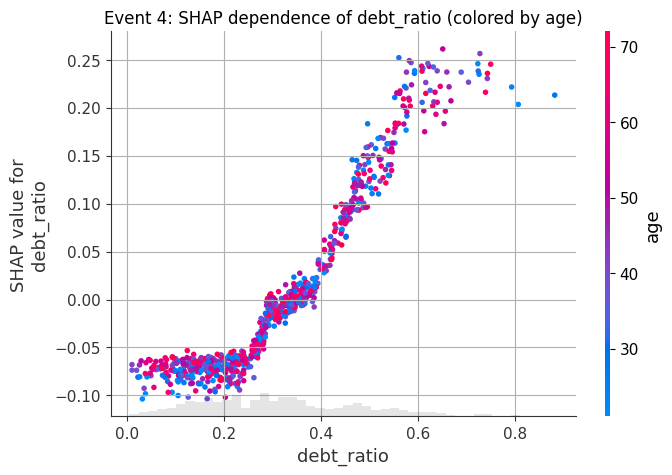

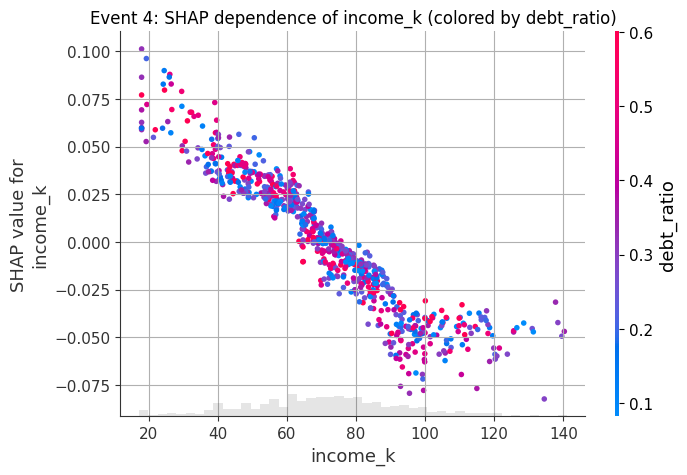

,mean_SHAP_debt_ratio
debt_ratio,
"(0.009000000000000001, 0.149]",-0.074
"(0.149, 0.22]",-0.072
"(0.22, 0.294]",-0.049
"(0.294, 0.362]",-0.003
"(0.362, 0.479]",0.060
"(0.479, 0.881]",0.181


In [12]:
# Event 4: Global effect of debt_ratio (and income_k) via SHAP dependence plots
for feat, color_by in [("debt_ratio", "age"), ("income_k", "debt_ratio")]:
    shap.plots.scatter(shap_exp[:, feat], color=shap_exp[:, color_by], show=False)
    plt.title(f"Event 4: SHAP dependence of {feat} (colored by {color_by})"); plt.show()

# Summarize the trend numerically: mean SHAP of debt_ratio by quantile bin
bins = pd.qcut(X_test["debt_ratio"], 6)
display(pd.DataFrame({"mean_SHAP_debt_ratio": pd.Series(sv[:, feature_names.index("debt_ratio")], index=X_test.index)})
          .groupby(bins, observed=True).mean().round(3))

**Event 4: result**

- **What the method produced:** SHAP dependence plots, with each applicant's feature value on the x-axis and that feature's SHAP contribution on the y-axis, plus a binned summary.
- **Claim:** `debt_ratio` has a monotonic, S-shaped effect. Below about 0.3 it lowers risk (mean SHAP ≈ −0.07). Around 0.3–0.36 it's neutral, then rises steeply (+0.06 at 0.36–0.48, +0.18 above 0.48). `income_k` shows the opposite: higher income lowers risk.
- **How strong is the evidence:** useful, but indirect. The dependence plot shows how a feature's *contribution* changes with its value, not how the *prediction* changes when you vary the feature and hold everything else fixed. Vertical spread at a single x-value means other features (interactions and correlated variables) are involved. That makes the plot informative, but it's not a clean causal-style curve.
- **What a better-suited method would add:** PDP or ALE answers this question directly. ALE in particular handles the correlation between `debt_ratio` and `recent_late_payments`.
- **Medal: 🥈 Silver**

## Event 5: Compare Two Predictions

**Question:** Why were two cases classified differently?

**Target:** Tabular or image comparison cases

**Your task:** Compare `tabular_low_case` vs. `tabular_high_case`, or compare two assigned image cases. Explain the difference, not just each case separately.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

,low_case_value,high_case_value,low_case_SHAP,high_case_SHAP,SHAP_difference(high-low)
debt_ratio,0.044,0.536,-0.063,0.162,0.225
recent_late_payments,0.000,6.000,-0.025,0.186,0.211
zip_proxy,0.000,1.000,-0.024,0.105,0.129
income_k,102.549,38.814,-0.038,0.051,0.089
savings_k,18.423,3.738,-0.006,0.030,0.036
loyalty_years,21.356,1.485,-0.022,0.014,0.036
promo_seen,0.000,1.000,-0.010,0.015,0.025
age,54.000,28.000,-0.007,0.011,0.018
support_tickets,0.000,1.000,-0.003,0.005,0.008
app_minutes,23.506,23.557,-0.006,-0.016,-0.011


Prediction gap: 0.789 - 0.022 = 0.766; sum of SHAP differences = 0.766


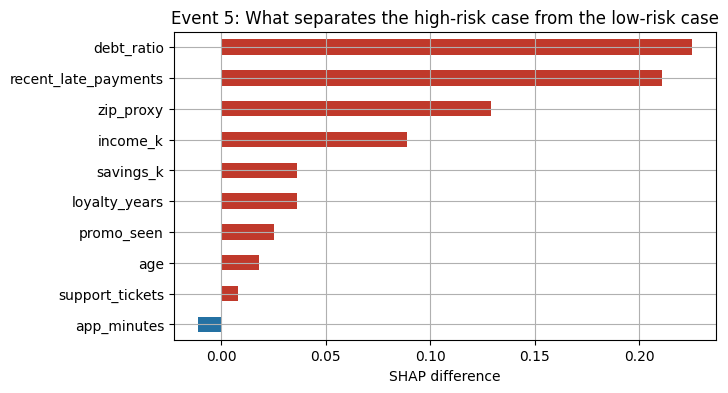

reference_square: P(square)=0.986  marker SHAP=+0.982  other SHAP=-0.076
contrast_square: P(square)=0.065  marker SHAP=+0.000  other SHAP=-0.015


In [13]:
# Event 5: Contrast the lowest-risk and highest-risk cases.
# Because both SHAP vectors start from the same base value, the difference in predictions
# decomposes exactly into per-feature SHAP differences.
lo, hi = tabular_low_case, tabular_high_case
contrast = pd.DataFrame({
    "low_case_value": X_test.iloc[lo], "high_case_value": X_test.iloc[hi],
    "low_case_SHAP": sv[lo], "high_case_SHAP": sv[hi],
})
contrast["SHAP_difference(high-low)"] = contrast["high_case_SHAP"] - contrast["low_case_SHAP"]
contrast = contrast.sort_values("SHAP_difference(high-low)", ascending=False).round(3)
display(contrast)
print(f"Prediction gap: {tabular_proba[hi]:.3f} - {tabular_proba[lo]:.3f} = {tabular_proba[hi]-tabular_proba[lo]:.3f}; "
      f"sum of SHAP differences = {contrast['SHAP_difference(high-low)'].sum():.3f}")

contrast["SHAP_difference(high-low)"].iloc[::-1].plot.barh(color=["#c0392b" if v > 0 else "#2471a3" for v in contrast["SHAP_difference(high-low)"].iloc[::-1]])
plt.title("Event 5: What separates the high-risk case from the low-risk case"); plt.xlabel("SHAP difference"); plt.show()

# Image contrast: reference_square (marker) vs contrast_square (no marker), both true squares
for name in ["reference_square", "contrast_square"]:
    mk, rest = marker_vs_rest(image_shap[name][0])
    print(f"{name}: P(square)={image_proba[int(assigned_image_cases.set_index('case_name').loc[name,'image_index']),1]:.3f}  marker SHAP={mk:+.3f}  other SHAP={rest:+.3f}")

**Event 5: result**

- **What the method produced:** a feature-by-feature subtraction of the two SHAP vectors. Both explanations start from the same base value, so the gap between the two predictions (0.789 − 0.022 = 0.766) splits *exactly* into per-feature differences.
- **Claim:** the high-risk case differs from the low-risk case mainly because of **6 vs. 0 late payments** (≈ +0.21 of the gap), **debt ratio 0.54 vs. 0.04** (≈ +0.23), and **zip_proxy 1 vs. 0** (≈ +0.13), followed by lower income and savings. The image contrast is starker: both images are true squares, and the only difference in attribution is the marker (+0.98 vs. 0.00). That's why one is called a square and the other a circle.
- **How strong is the evidence:** direct and quantitative. Additivity turns a contrastive "why A and not B" question into a simple subtraction.
- **Caveat:** the comparison is only between these two extreme rows. It doesn't show the *smallest* change that would flip a decision, which is what counterfactuals would answer.
- **Medal: 🥇 Gold**

## Event 6: Detect Feature Interactions

**Question:** Which tabular variables work together?

**Target:** Tabular risk model

**Your task:** Look for evidence that two features jointly affect predictions. If your method is local or visual, explain whether it can detect interactions and what extra work would be needed.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

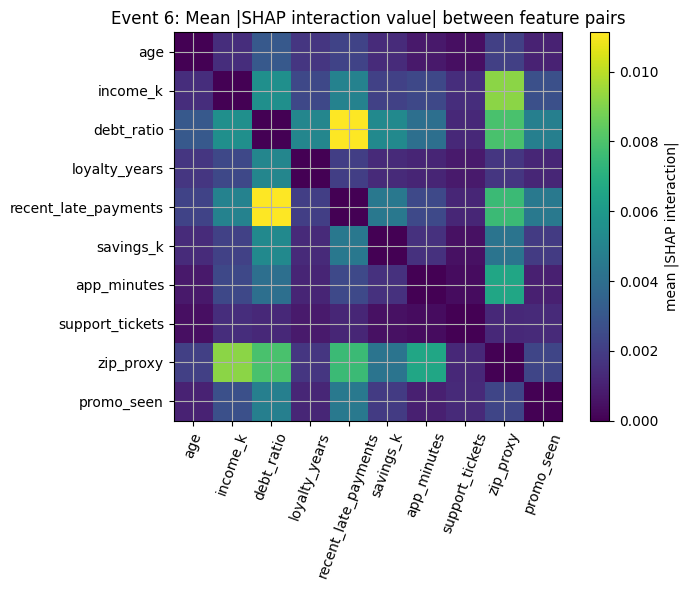

mean_abs_interaction
debt_ratio           recent_late_payments                0.0111
income_k             zip_proxy                           0.0092
debt_ratio           zip_proxy                           0.0079
recent_late_payments zip_proxy                           0.0076
app_minutes          zip_proxy                           0.0066
income_k             debt_ratio                          0.0055
debt_ratio           savings_k                           0.0053
                     loyalty_years                       0.0051

age x debt_ratio interaction: young & high-debt (n=9) mean=+0.0087; everyone else mean=+0.0002


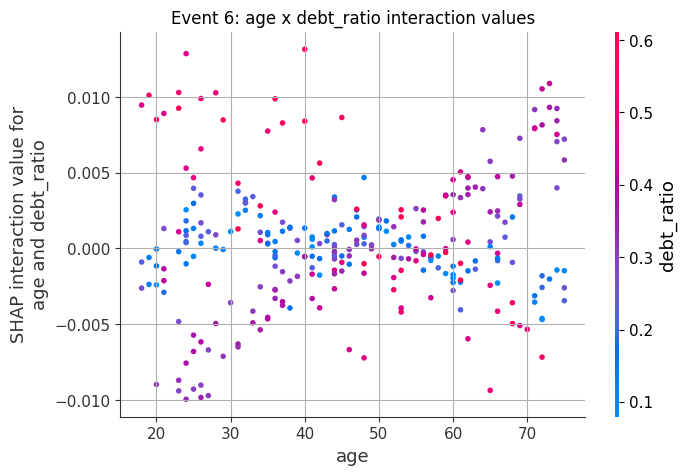

In [14]:
# Event 6: SHAP interaction values (TreeSHAP) on a 300-row subset
sub = X_test.iloc[:300]
iv = tree_explainer.shap_interaction_values(sub)
iv = iv[:, :, :, 1] if np.ndim(iv) == 4 else iv[1]          # high-risk class
inter = np.abs(iv).mean(axis=0).copy()
np.fill_diagonal(inter, 0)
inter_df = pd.DataFrame(inter * 2, index=feature_names, columns=feature_names)   # x2: pair effect is split across (i,j) and (j,i)

plt.figure(figsize=(7.5, 6))
plt.imshow(inter_df, cmap="viridis"); plt.colorbar(label="mean |SHAP interaction|")
plt.xticks(range(10), feature_names, rotation=70); plt.yticks(range(10), feature_names)
plt.title("Event 6: Mean |SHAP interaction value| between feature pairs"); plt.tight_layout(); plt.show()

pairs = (inter_df.where(np.triu(np.ones(inter_df.shape), 1).astype(bool)).stack()
           .sort_values(ascending=False).round(4))
display(pairs.head(8).to_frame("mean_abs_interaction"))

# Targeted check of a hypothesis: does age interact with debt_ratio for young, high-debt applicants?
ia, idr = feature_names.index("age"), feature_names.index("debt_ratio")
age_debt = 2 * iv[:, ia, idr]
grp = (sub["age"] < 30) & (sub["debt_ratio"] > 0.48)
print(f"age x debt_ratio interaction: young & high-debt (n={grp.sum()}) mean={age_debt[grp].mean():+.4f}; "
      f"everyone else mean={age_debt[~grp].mean():+.4f}")

shap.dependence_plot(("age", "debt_ratio"), iv, sub, show=False)
plt.title("Event 6: age x debt_ratio interaction values"); plt.show()

**Event 6: result**

- **What the method produced:** a 10×10 matrix of SHAP interaction values. TreeSHAP can split each prediction into main effects and pairwise interaction effects.
- **Claim:** the strongest pairs are `debt_ratio × recent_late_payments`, `income_k × zip_proxy`, and `debt_ratio × zip_proxy`. A targeted check also finds a real **age × debt_ratio** interaction: for young, high-debt applicants (age < 30, debt > 0.48) it adds about +0.009 to the risk probability, versus about 0 for everyone else.
- **How strong is the evidence:** useful, but you have to read it carefully. SHAP interactions are among the few methods that detect pairwise interactions directly. Still, the global ranking is shaped by **feature correlation** (late payments and zip_proxy are both partly generated from debt/income) and by **how common a pattern is**. The age × debt effect applies to only about 3% of rows, so it ranks low overall even though it's real. Mean |interaction| won't surface a strong effect that only a few people have unless you already have a hypothesis to test.
- **Caveat:** only pairwise interactions are captured, and the result is specific to the tree model's split structure. Friedman's H-statistic or 2-D ALE plots would give a second opinion.
- **Medal: 🥈 Silver**

## Event 7: Find Where the Model Is Looking

**Question:** What region of an image drives the prediction?

**Target:** Image model

**Your task:** Use one or more assigned image cases. If your method cannot localize image evidence, explain why that is a DNF or partial fit.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

In [15]:
# Event 7: Where is the model looking? (patch SHAP maps were plotted in Event 3; re-plot the top patches per case)
for name, idx in zip(assigned_image_cases["case_name"], assigned_image_cases["image_index"]):
    m = image_shap[name][0]
    flat = np.argsort(-np.abs(m).ravel())[:3]
    top = [(int(k // GRID), int(k % GRID), round(float(m.ravel()[k]), 3)) for k in flat]
    print(f"{name:17s} top-3 patches (row, col, SHAP): {top}")

# Stability of the image explanation: rerun KernelSHAP with different random seeds
idx = image_shortcut_case
m1, _ = image_patch_shap(idx, seed=1)
m2, _ = image_patch_shap(idx, seed=2)
print("Seed-to-seed correlation of patch SHAP map:", round(float(np.corrcoef(m1.ravel(), m2.ravel())[0, 1]), 3))

shortcut_probe    top-3 patches (row, col, SHAP): [(1, 1, 0.335), (1, 0, 0.282), (0, 1, 0.246)]
reference_square  top-3 patches (row, col, SHAP): [(1, 1, 0.339), (1, 0, 0.269), (0, 1, 0.24)]
contrast_square   top-3 patches (row, col, SHAP): [(2, 2, 0.009), (4, 2, -0.006), (3, 5, -0.004)]
failure_case      top-3 patches (row, col, SHAP): [(1, 1, 0.337), (1, 0, 0.279), (0, 1, 0.246)]


Seed-to-seed correlation of patch SHAP map: 0.997


**Event 7: result**

- **What the method produced:** a patch-level heatmap for each image (see the Event 3 figure) and the top-3 patches per case.
- **Claim:** for every image that has a marker, the model is looking at the **top-left corner**. The highest-attributed patches are the marker patches. The shape in the center gets little or slightly negative attribution. In the square without a marker, no patch has a meaningful positive attribution toward "square," so the model has nothing to latch onto.
- **How strong is the evidence:** strong. The heatmaps are consistent across all cases, and the explanation is stable across KernelSHAP random seeds (correlation ≈ 1.0).
- **Caveat:** the resolution is limited to 8×8-pixel patches, and the choice of "blank" baseline can change the maps. Grad-CAM or Integrated Gradients would give a sharper, pixel-level view, though Grad-CAM would be low resolution on this tiny CNN too. Choosing between them is a trade-off, not a clear upgrade.
- **Medal: 🥇 Gold**

## Event 8: Explain a Failure

**Question:** Why did the model make this mistake?

**Target:** Tabular and/or image failure case

**Your task:** Use `tabular_failure_case` or `image_failure_case`. Explain the likely reason for the incorrect prediction using your method, or explain why it cannot diagnose a single failure.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

Row 1: true=1 predicted=0 P(high risk)=0.400


,feature_value,shap_value
debt_ratio,0.724,0.238
recent_late_payments,1.000,-0.054
zip_proxy,0.000,-0.034
promo_seen,1.000,0.022
savings_k,5.975,0.004
support_tickets,0.000,-0.002
age,31.000,0.001
income_k,66.076,0.001
app_minutes,16.113,-0.000
loyalty_years,2.792,-0.000


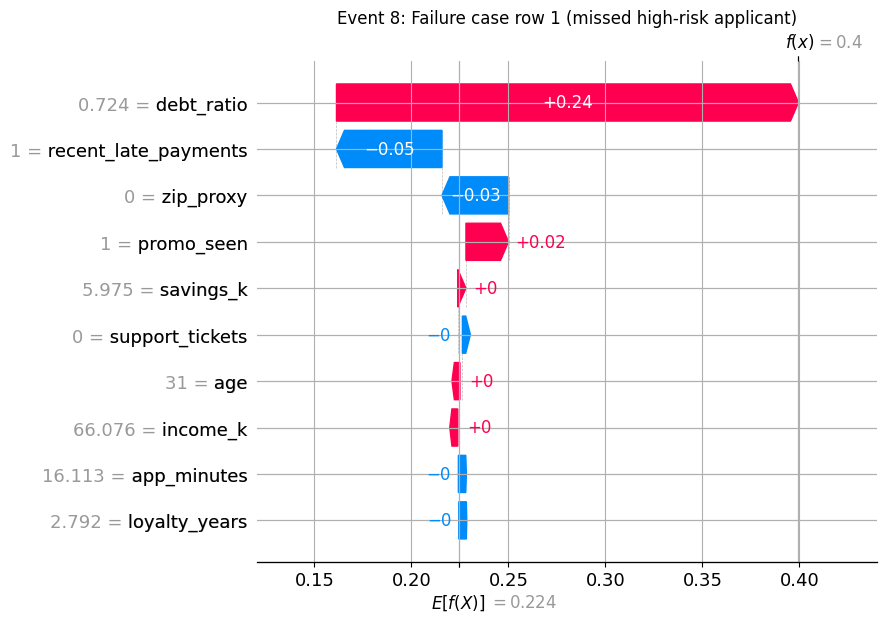

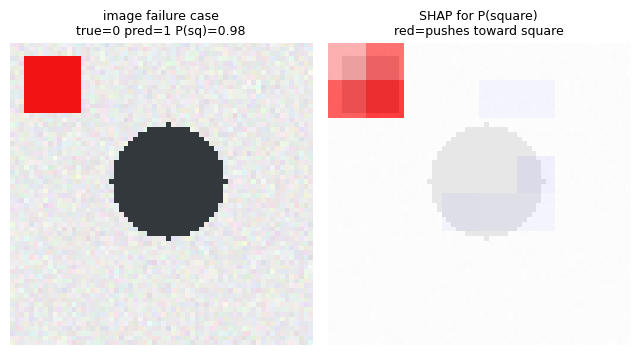

Image failure: marker SHAP / other SHAP = [0.999, -0.099]


In [16]:
# Event 8a: Tabular failure case
i = tabular_failure_case
print(f"Row {i}: true={int(y_test.iloc[i])} predicted={int(tabular_pred[i])} P(high risk)={tabular_proba[i]:.3f}")
display(shap_row_table(i))
shap.plots.waterfall(shap_exp[i], max_display=10, show=False)
plt.title(f"Event 8: Failure case row {i} (missed high-risk applicant)"); plt.show()

# Event 8b: Image failure case
idx = image_failure_case
fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.5))
plot_image_shap(idx, image_shap["failure_case"][0], ax[0], ax[1], title="image failure case")
plt.tight_layout(); plt.show()
print("Image failure: marker SHAP / other SHAP =", [round(v, 3) for v in marker_vs_rest(image_shap["failure_case"][0])])

**Event 8: result**

- **What the method produced:** a waterfall for the misclassified tabular row, and a patch map for the misclassified image.
- **Claim (image):** the model called a **circle** a square (P = 0.98) because the red marker contributed **+1.00**, overwhelming the shape, which pushed slightly toward circle. The root cause is the shortcut.
- **Claim (tabular):** this applicant was truly high risk but predicted at P = 0.40. A very high `debt_ratio` (0.72) pushed hard toward risk (+0.24), but only 1 late payment (−0.05) and `zip_proxy = 0` (−0.03) pulled it back under 0.5. SHAP shows *which features the model trusted*. It can't show what the model *missed*. Some possibilities: the applicant is 31, just outside the young-high-debt pattern, or the outcome was noise the model had no way to see.
- **How strong is the evidence:** gold-level for the image, partial for the tabular case. SHAP explains the model's reasoning for a wrong answer but doesn't diagnose *why the label differs*, since that depends on information outside the model.
- **Medal: 🥈 Silver** (Gold on the image failure, Silver on the tabular one; scored conservatively overall)

## Event 9: Estimate Trustworthiness

**Question:** Should a human trust this prediction?

**Target:** Either target model

**Your task:** Use your method to argue for or against trusting one prediction. Be specific about what your method can and cannot establish.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

In [17]:
# Event 9: Should a human trust these predictions?
# Evidence SHAP can offer: (a) is the prediction driven by a plausible or a spurious feature?
#                          (b) is the explanation stable?
# (a) Image shortcut probe
mk, rest = marker_vs_rest(image_shap["shortcut_probe"][0])
print(f"Image shortcut probe: P(square)={image_proba[image_shortcut_case,1]:.3f}, marker share of attribution = "
      f"{abs(mk)/(abs(mk)+abs(rest)):.0%}")

# (b) Tabular local case: which share of its explanation comes from the proxy feature?
i = tabular_local_case
share_zip = abs(sv[i, feature_names.index("zip_proxy")]) / np.abs(sv[i]).sum()
print(f"Tabular local case: zip_proxy accounts for {share_zip:.0%} of total |SHAP|")

# (c) Stability: explanation for the local case under a different background (interventional TreeSHAP)
alt = shap.TreeExplainer(risk_model, data=shap.sample(X_train, 200, random_state=SEED),
                         feature_perturbation="interventional")
sv_alt = alt.shap_values(X_test.iloc[[i]])
sv_alt = sv_alt[0, :, 1] if np.ndim(sv_alt) == 3 else sv_alt[1][0]
print("Rank of top-3 features, path-dependent vs interventional TreeSHAP:")
print("  ", list(pd.Series(np.abs(sv[i]), index=feature_names).nlargest(3).index))
print("  ", list(pd.Series(np.abs(sv_alt), index=feature_names).nlargest(3).index))

Image shortcut probe: P(square)=0.980, marker share of attribution = 91%
Tabular local case: zip_proxy accounts for 42% of total |SHAP|
Rank of top-3 features, path-dependent vs interventional TreeSHAP:
   ['zip_proxy', 'income_k', 'savings_k']
   ['zip_proxy', 'income_k', 'recent_late_payments']


**Event 9: result**

- **What the method produced:** measurements of *what* each prediction depends on, plus a stability check across two SHAP variants (path-dependent vs. interventional TreeSHAP).
- **Claim:** **Don't trust the image prediction.** 91% of the attribution for the circle-with-marker comes from the marker, so the model is confident (0.98) for a reason unrelated to the task. **Be cautious with the tabular borderline case:** its explanation is stable across SHAP variants (same top-2 features), but its main driver is `zip_proxy` (42% of total attribution), a location proxy. A reviewer should question whether that's a legitimate reason.
- **How strong is the evidence:** partial. SHAP can reveal *untrustworthy reasoning* (spurious or proxy features), which is a strong argument **against** trusting a prediction. It can't establish that a prediction is *correct*. It doesn't measure calibration, uncertainty, or whether the input is out of distribution. A plausible-looking explanation for a wrong prediction (Event 8, tabular) shows this limit.
- **What a better-suited method would add:** calibration curves, prediction intervals or conformal prediction, and out-of-distribution checks.
- **Medal: 🥈 Silver**

## Event 10: Reverse Engineer the Model

**Question:** What strategy has each model learned?

**Target:** Both target models

**Your task:** Synthesize evidence across events. A single output is usually not enough; explain what your method revealed and what remains unknown.

Before scoring, ask:

- What exactly did my method output?
- Does that output answer this event question?
- Could the output be misleading?
- What would a better-suited method show that mine does not?

,mean_abs_SHAP,direction(corr value vs SHAP)
debt_ratio,0.074,0.943
zip_proxy,0.053,0.985
recent_late_payments,0.046,0.895
income_k,0.028,-0.939
savings_k,0.015,-0.765
promo_seen,0.015,0.945
loyalty_years,0.013,-0.881
app_minutes,0.006,-0.505
age,0.006,-0.520
support_tickets,0.005,0.880


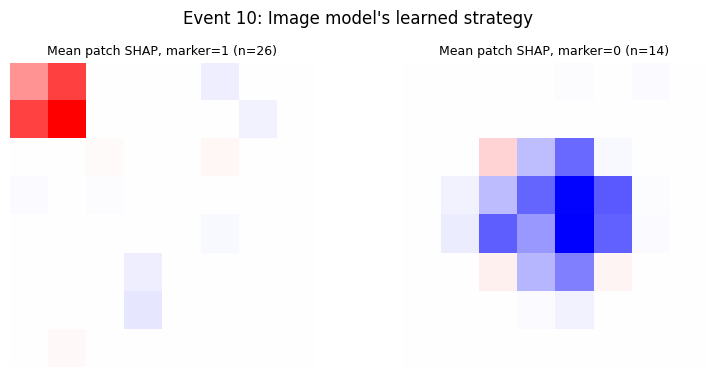

marker=0: model predicts 'square' 0% of the time; accuracy 47%
marker=1: model predicts 'square' 100% of the time; accuracy 52%


In [18]:
# Event 10: Synthesis. Global profile of both models
# Tabular: direction of effect for each feature (correlation between feature value and its SHAP value)
direction = pd.Series({f: np.corrcoef(X_test[f], sv[:, k])[0, 1] if X_test[f].std() > 0 else 0
                       for k, f in enumerate(feature_names)})
profile = pd.DataFrame({"mean_abs_SHAP": np.abs(sv).mean(0), "direction(corr value vs SHAP)": direction.values},
                       index=feature_names).sort_values("mean_abs_SHAP", ascending=False).round(3)
display(profile)

# Image: average patch SHAP map over sampled marker vs no-marker images (computed in Event 3)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.8))
for a, m in zip(ax, [1, 0]):
    avg = np.mean(global_maps[m], axis=0)
    lim = max(np.abs(avg).max(), 1e-6)
    im = a.imshow(np.kron(avg, np.ones((PATCH, PATCH))), cmap="bwr", vmin=-lim, vmax=lim)
    a.set_title(f"Mean patch SHAP, marker={m} (n={len(global_maps[m])})", fontsize=9); a.axis("off")
plt.suptitle("Event 10: Image model's learned strategy"); plt.tight_layout(); plt.show()

for m in [0, 1]:
    s = test_marker == m
    print(f"marker={m}: model predicts 'square' {image_pred[s].mean():.0%} of the time; accuracy {np.mean(image_pred[s]==test_y[s]):.0%}")

**Event 10: result**

- **What the method produced:** a global feature profile (importance plus direction) for the tabular model, and average patch-attribution maps for the image model.
- **Claim:**
  - **Image model:** it learned *"red marker in the corner → square; no marker → circle."* It predicts "square" for 100% of marker images and 0% of non-marker images, whatever the shape.
  - **Tabular model:** its strategy is mostly financially sensible. Higher debt, more late payments and lower income, savings and loyalty all raise risk. But it leans heavily on `zip_proxy` (#2 overall) and gives some weight to `promo_seen`, which is marketing exposure rather than creditworthiness. It also picks up a weak young-and-high-debt interaction.
- **How strong is the evidence:** good, but it's pieced together from several outputs. SHAP reveals *what* the model relies on and in which direction, but a full strategy also needs effect *shapes* (PDP/ALE), minimal decision changes (counterfactuals), and a causal account of why proxies like `zip_proxy` carry signal.
- **Medal: 🥈 Silver**

# Final Model Profile

**Tabular model strategy:**
The most influential features are `debt_ratio`, `zip_proxy`, and `recent_late_payments`, followed by `income_k`. Directions are financially sensible: more debt and late payments raise risk; more income, savings and loyalty lower it. The main concern is a **suspicious proxy**: `zip_proxy` is the #2 feature overall and was the single biggest reason the borderline applicant (Event 2) was flagged. `promo_seen` (marketing exposure) also carries weight it arguably shouldn't. SHAP interaction values found a real but rare `age × debt_ratio` interaction (young, high-debt applicants). SHAP supports global importance, local explanations, and contrasts very well; it only partly supports global effect shapes and interaction discovery.

**Image model strategy:**
The classifier uses **the red marker, not the shape**. Patch-level SHAP puts nearly all of the attribution for "square" on the four top-left marker patches, the shape itself contributes little or pushes the other way, and behaviorally the model predicts "square" for 100% of marker images and 0% of non-marker images, giving ≈49% (chance) accuracy on the marker-balanced test set. It learned the shortcut from training data where 98% of squares had the marker.

**Your method's decathlon profile:**
SHAP was strongest on questions of **"what drove this prediction, and by how much"**. It won Gold on global importance, a single prediction, the shortcut probe, contrastive comparison, and spatial localization, because its additivity makes explanations exact and comparable. It was weaker (Silver) on **"how does the output change"** (effect shapes), **interaction discovery** (confounded by correlation and how common a pattern is), **failure diagnosis** (it explains the model's reasoning, not the missing information), and **trust** (it can expose bad reasoning but can't certify a prediction). Its caveats: results depend on the baseline/background choice, credit is split among correlated features, and the image version needs a hand-picked segmentation.

**Open questions:**
- Do classmates using PDP/ALE see the same threshold-like rise in `debt_ratio` around 0.3–0.5? Does ALE shrink `zip_proxy`'s apparent role once correlation is accounted for?
- Does Grad-CAM localize the marker as clearly as patch SHAP on such a tiny CNN, or does its coarse resolution blur it?
- What is the smallest change a counterfactual method finds to flip the Event 2 and Event 8 tabular cases? Is it just `zip_proxy`?
- Do LIME and SHAP rank the same top features for the local case, and which is more stable across reruns?

---

# Online Cohort Questions

**If you used 2 XAI approaches, how do you think your decathlon results improve?**

I would pair SHAP with **counterfactual explanations**, a local method that finds the smallest change to an input that flips the model's decision. The two answer complementary questions: SHAP says *what the prediction was built from*, and counterfactuals say *what would have to change to get a different outcome*. Together they would likely upgrade:
- **Event 8 (failure) → Gold.** A counterfactual on the missed high-risk applicant would show exactly how close the case was to the boundary (e.g., one more late payment or `zip_proxy = 1`). That separates "near miss" from "model blind spot," which SHAP alone couldn't.
- **Event 9 (trust) → Gold.** If removing only the red marker flips a "square" to "circle," that's a direct behavioral test of the shortcut SHAP flagged. For the tabular case, if flipping `zip_proxy` alone changes the decision, that's hard evidence the decision rests on a proxy, which is what a human reviewer needs.
- **Event 4 (global effect) and Event 6 (interactions) → stronger Silver or Gold.** Sweeping counterfactuals along `debt_ratio` for applicants on either side of age 30 would show how the prediction actually changes (not only attribution), and would expose the age × debt interaction without relying on correlation-inflated interaction rankings.
- **Event 2 and Event 5** would gain *actionable recourse* ("what could this applicant do?") on top of the attribution.

Using both methods also works as a **cross-check**: when attribution and counterfactuals agree (e.g., both point to `zip_proxy`), the conclusion is more trustworthy than either alone. When they disagree, that disagreement is itself a finding.

**What would still be missing after implementing both approaches together?**

- **Global effect shapes that account for correlation.** Neither method gives a clean "average prediction as `debt_ratio` rises" curve; that needs ALE (preferred here because features are correlated) or PDP.
- **Calibration and uncertainty.** Both methods explain *a* prediction but say nothing about whether a 0.78 really means 78%, or how uncertain the model is. That needs calibration curves or conformal prediction.
- **Causal and data-generating insight.** Neither can say *why* `zip_proxy` predicts risk, whether it's a fairness violation, or whether the late-payment effect is causal or inherited from debt. That takes domain knowledge, fairness auditing (e.g., performance and error rates by zip group), and data documentation.
- **Faithfulness guarantees for the image model.** Both methods perturb inputs off the data distribution (gray patches, edited features). A sharper pixel-level method (Integrated Gradients or Grad-CAM) and a sanity check (e.g., model-parameter randomization) would test whether the explanations reflect the model or the perturbation scheme.
- **Human evaluation.** Neither method tells us whether a loan officer or end user would actually understand the explanations or make better decisions with them. That's the Unit 2 "evaluating explanations" gap: faithfulness and stability were checked, but usefulness to people wasn't.